# 🎓 Student Exam Score Predictor - Exploratory Analysis

This notebook is for exploratory data analysis only. It does not train or save the model.

- Model training, cross-validation, tuning and saving live in `ml/train.py`.
- Run `python train.py` to rebuild `models/best_model.pkl` and `models/model_meta.json`.
- The last section of this notebook reads `model_meta.json` to show the latest results.

## 📋 Contents
1. Data loading and validation
2. Exploratory data analysis
3. Latest model results (from `train.py`)


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
sns.set(style="whitegrid")

# Works whether Jupyter starts in notebooks/ or in the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


## 📊 Data Loading and Initial Exploration


In [2]:
# Load the dataset
# The project dataset contains 1,000 student records with 15 columns total:
# 14 feature columns + 1 target column (`exam_score`).
df = pd.read_csv(ROOT / 'data' / 'student_habits_performance.csv')

print(f"📁 Dataset loaded successfully!")
print(f"📏 Shape: {df.shape}")
print(f"🔍 Columns: {list(df.columns)}")

# Quick peek at the data
df.head()


📁 Dataset loaded successfully!
📏 Shape: (1000, 16)
🔍 Columns: ['student_id', 'age', 'gender', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'part_time_job', 'attendance_percentage', 'sleep_hours', 'diet_quality', 'exercise_frequency', 'parental_education_level', 'internet_quality', 'mental_health_rating', 'extracurricular_participation', 'exam_score']


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [3]:
# Basic information about the dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

In [4]:
# Missing values. The training pipeline imputes them, so no rows are dropped.
print("Missing values:")
print(df.isna().sum())

print()
print(f"Duplicate rows: {df.duplicated().sum()}")


Missing values:
student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

Duplicate rows: 0


In [5]:
# Statistical summary
print("📊 Statistical Summary - Numerical Columns:")
df.describe()


📊 Statistical Summary - Numerical Columns:


,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,1000.0000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.4980,3.55010,2.505500,1.819700,84.131700,6.470100,3.042000,5.438000,69.601500
std,2.3081,1.46889,1.172422,1.075118,9.399246,1.226377,2.025423,2.847501,16.888564
min,17.0000,0.00000,0.000000,0.000000,56.000000,3.200000,0.000000,1.000000,18.400000
25%,18.7500,2.60000,1.700000,1.000000,78.000000,5.600000,1.000000,3.000000,58.475000
50%,20.0000,3.50000,2.500000,1.800000,84.400000,6.500000,3.000000,5.000000,70.500000
75%,23.0000,4.50000,3.300000,2.525000,91.025000,7.300000,5.000000,8.000000,81.325000
max,24.0000,8.30000,7.200000,5.400000,100.000000,10.000000,6.000000,10.000000,100.000000


In [6]:
print("📊 Statistical Summary - Categorical Columns:")
df.describe(include="object")


📊 Statistical Summary - Categorical Columns:


C:\Users\Purab\AppData\Local\Temp\ipykernel_29636\2598220520.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,student_id,gender,part_time_job,diet_quality,parental_education_level,internet_quality,extracurricular_participation
count,1000,1000,1000,1000,909,1000,1000
unique,1000,3,2,3,3,3,2
top,S1000,Female,No,Fair,High School,Good,No
freq,1,481,785,437,392,447,682


## 📈 Data Visualization and Analysis


In [7]:
# Define categorical and numerical columns
categorical_cols = ["gender", "part_time_job", "diet_quality", "parental_education_level",
                   "internet_quality", "extracurricular_participation"]

num_features = ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
               'attendance_percentage', 'sleep_hours', 'exercise_frequency',
               'mental_health_rating']

print("📊 Categorical columns:", categorical_cols)
print("📊 Numerical features:", num_features)


📊 Categorical columns: ['gender', 'part_time_job', 'diet_quality', 'parental_education_level', 'internet_quality', 'extracurricular_participation']
📊 Numerical features: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']


In [8]:
# Value counts for categorical variables
for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())



Value counts for gender:
gender
Female    481
Male      477
Other      42
Name: count, dtype: int64

Value counts for part_time_job:
part_time_job
No     785
Yes    215
Name: count, dtype: int64

Value counts for diet_quality:
diet_quality
Fair    437
Good    378
Poor    185
Name: count, dtype: int64

Value counts for parental_education_level:
parental_education_level
High School    392
Bachelor       350
Master         167
Name: count, dtype: int64

Value counts for internet_quality:
internet_quality
Good       447
Average    391
Poor       162
Name: count, dtype: int64

Value counts for extracurricular_participation:
extracurricular_participation
No     682
Yes    318
Name: count, dtype: int64


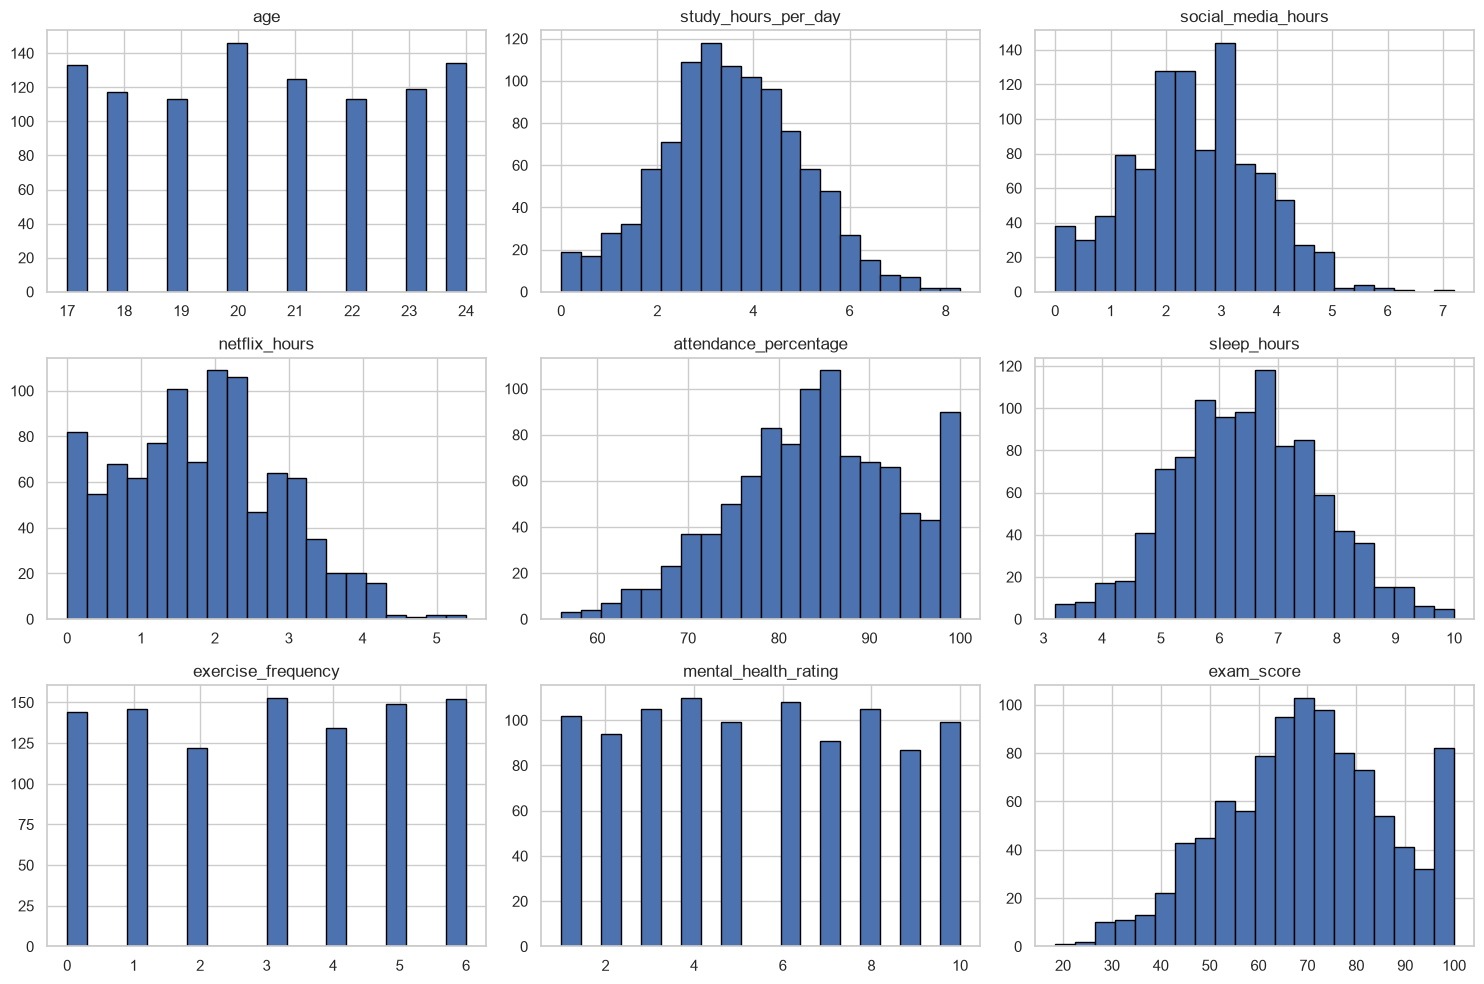

In [9]:
# Histogram plots for all numerical columns
df.hist(bins=20, edgecolor="black", figsize=(15, 10))
plt.tight_layout()
plt.show()


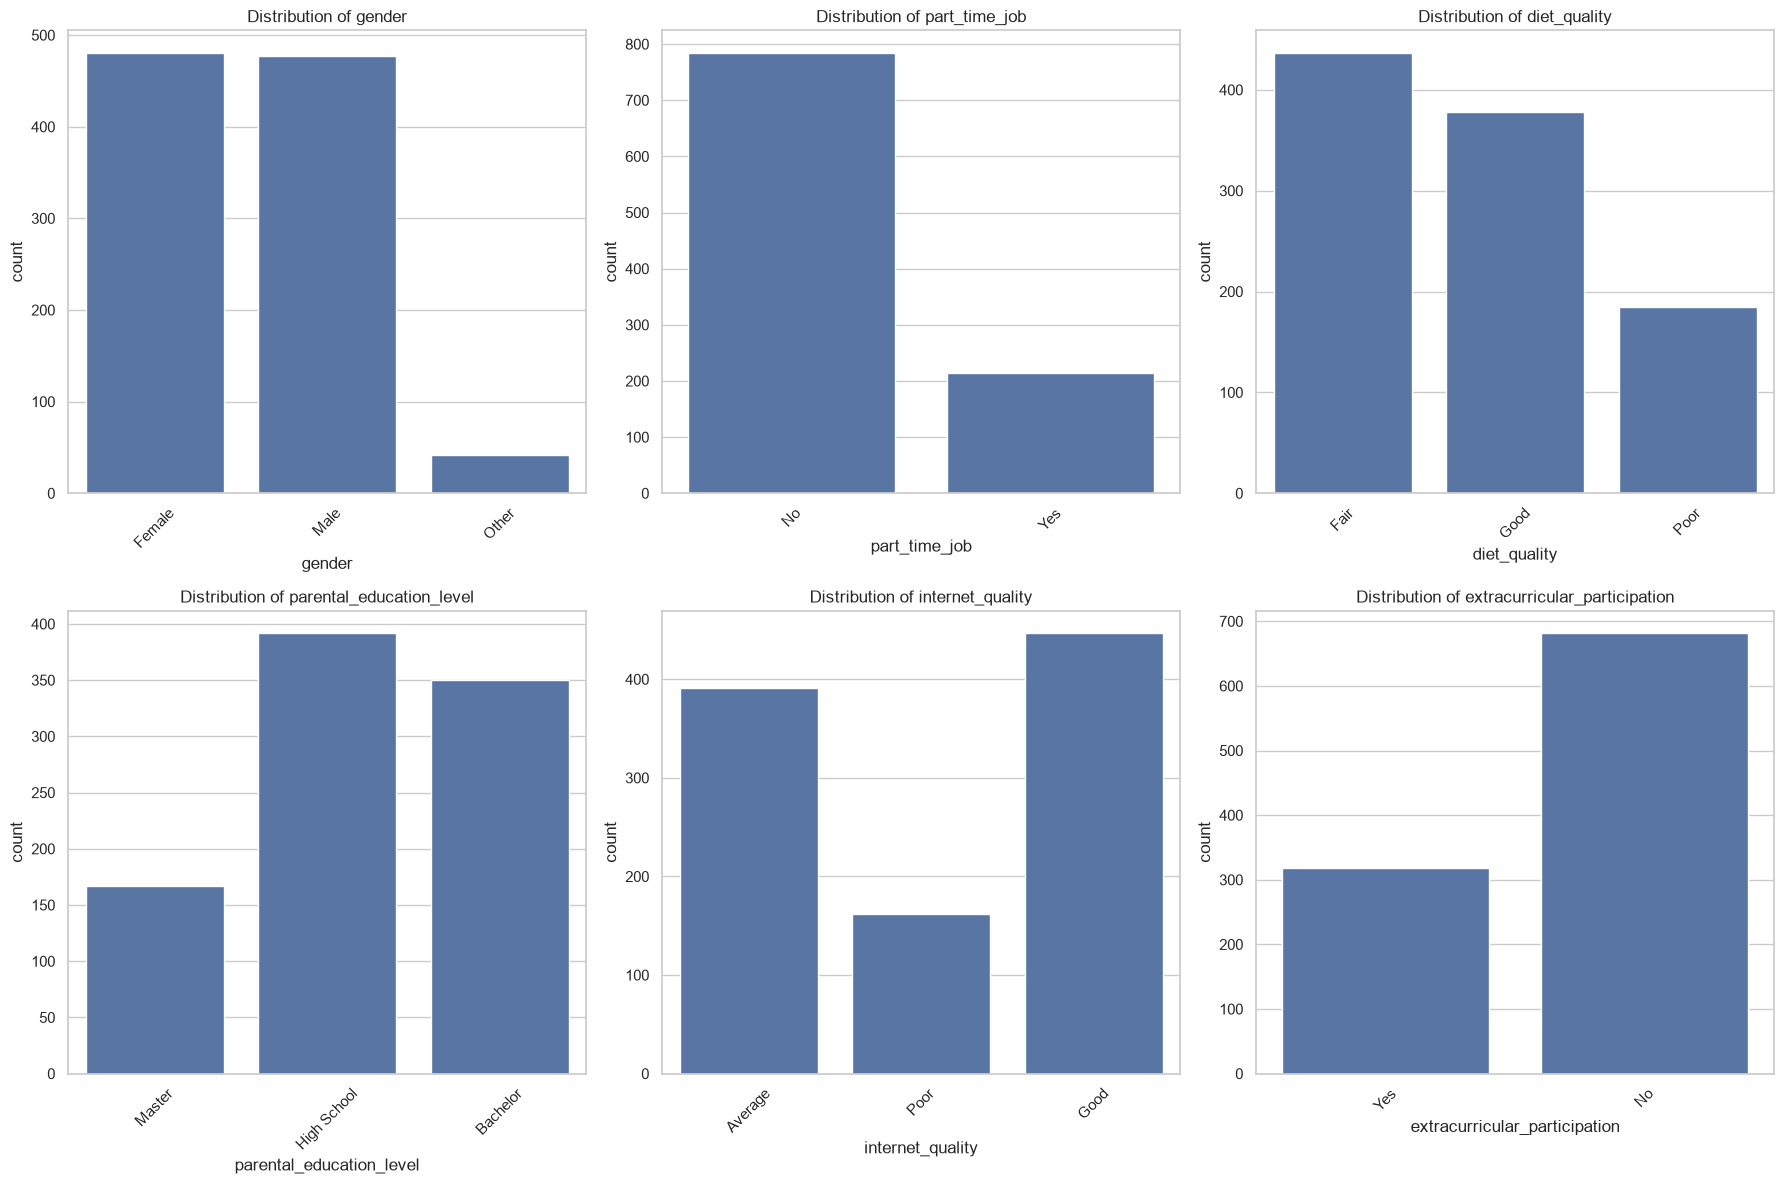

In [10]:
# Count plots for categorical variables
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


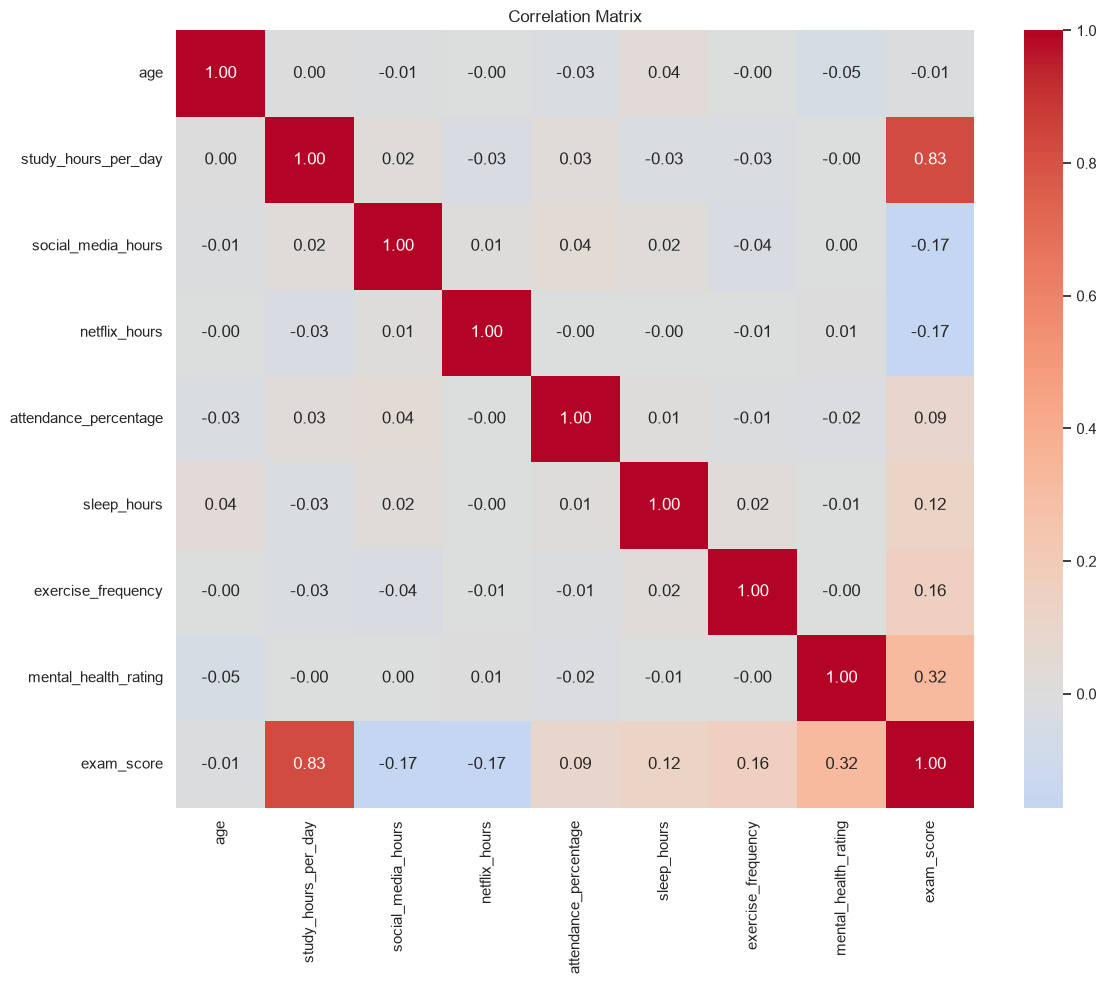

In [11]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


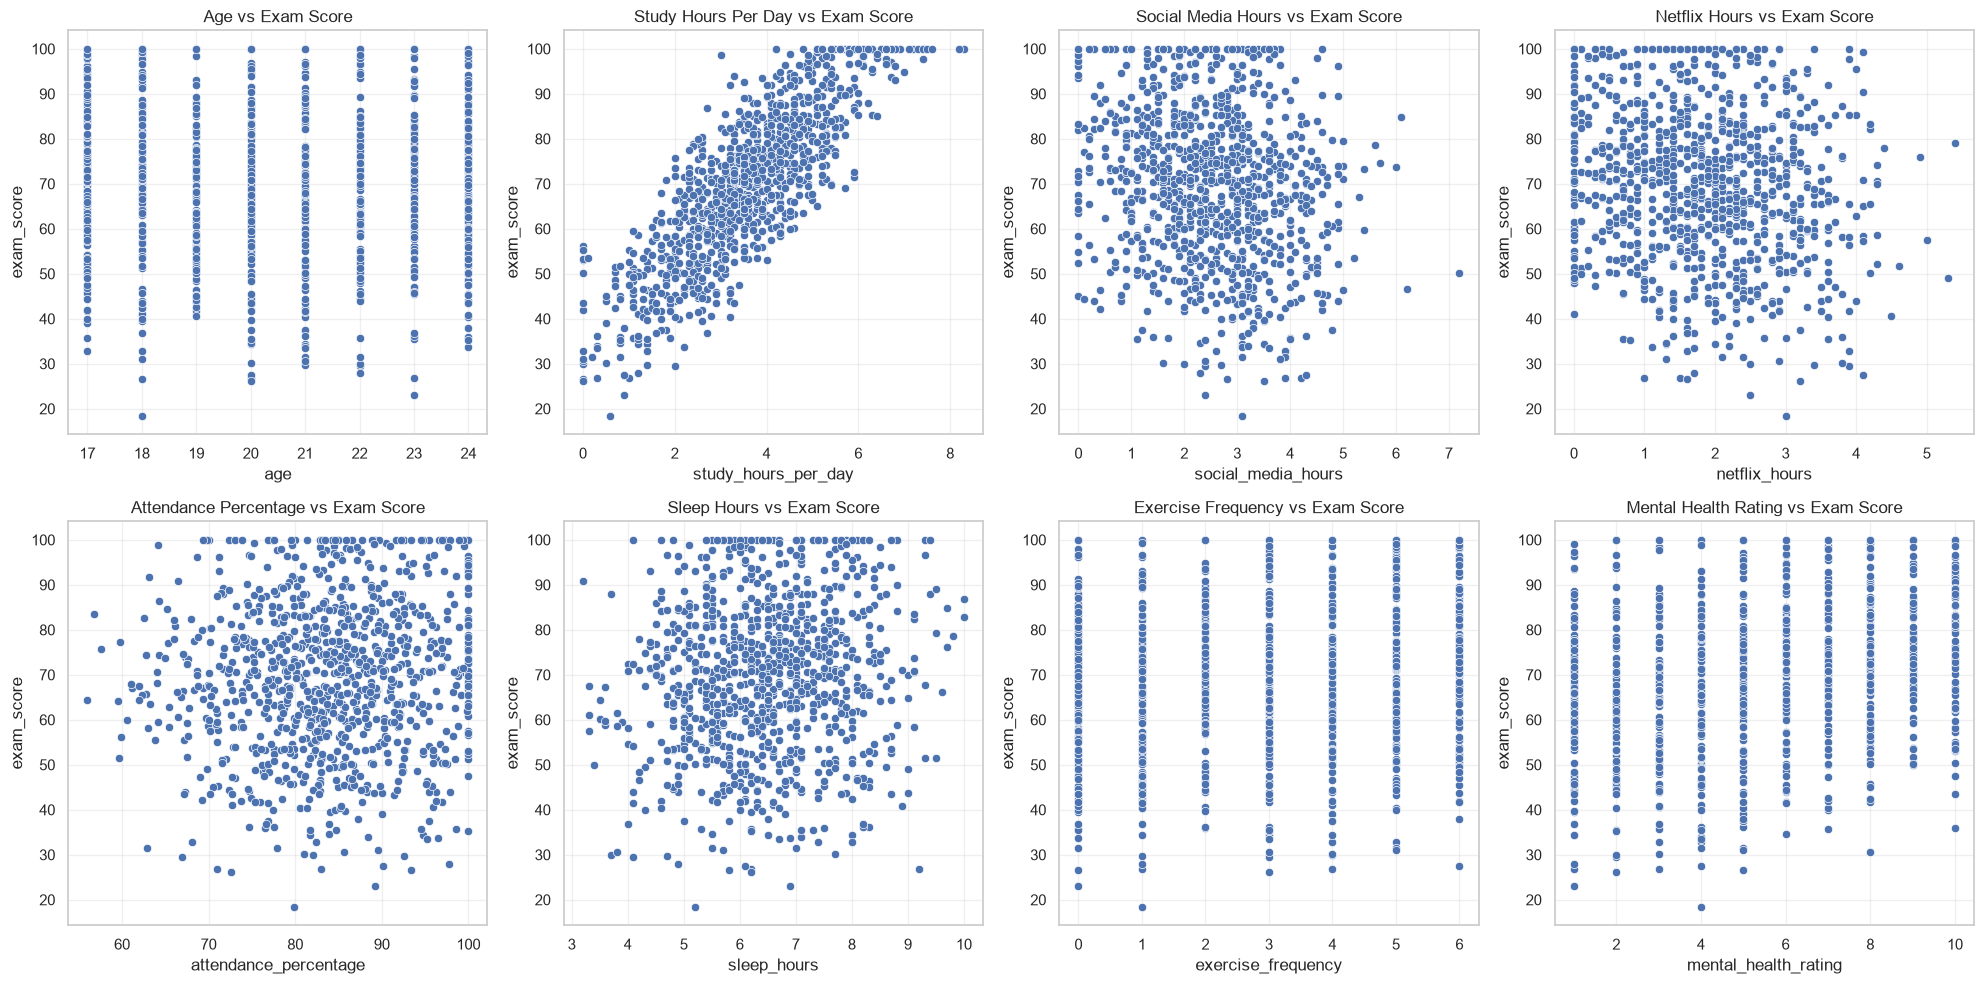

In [12]:
# Scatter plots: numerical features vs exam score
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feature in enumerate(num_features):
    sns.scatterplot(data=df, x=feature, y="exam_score", ax=axes[i])
    axes[i].set_title(f"{feature.replace('_', ' ').title()} vs Exam Score")
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


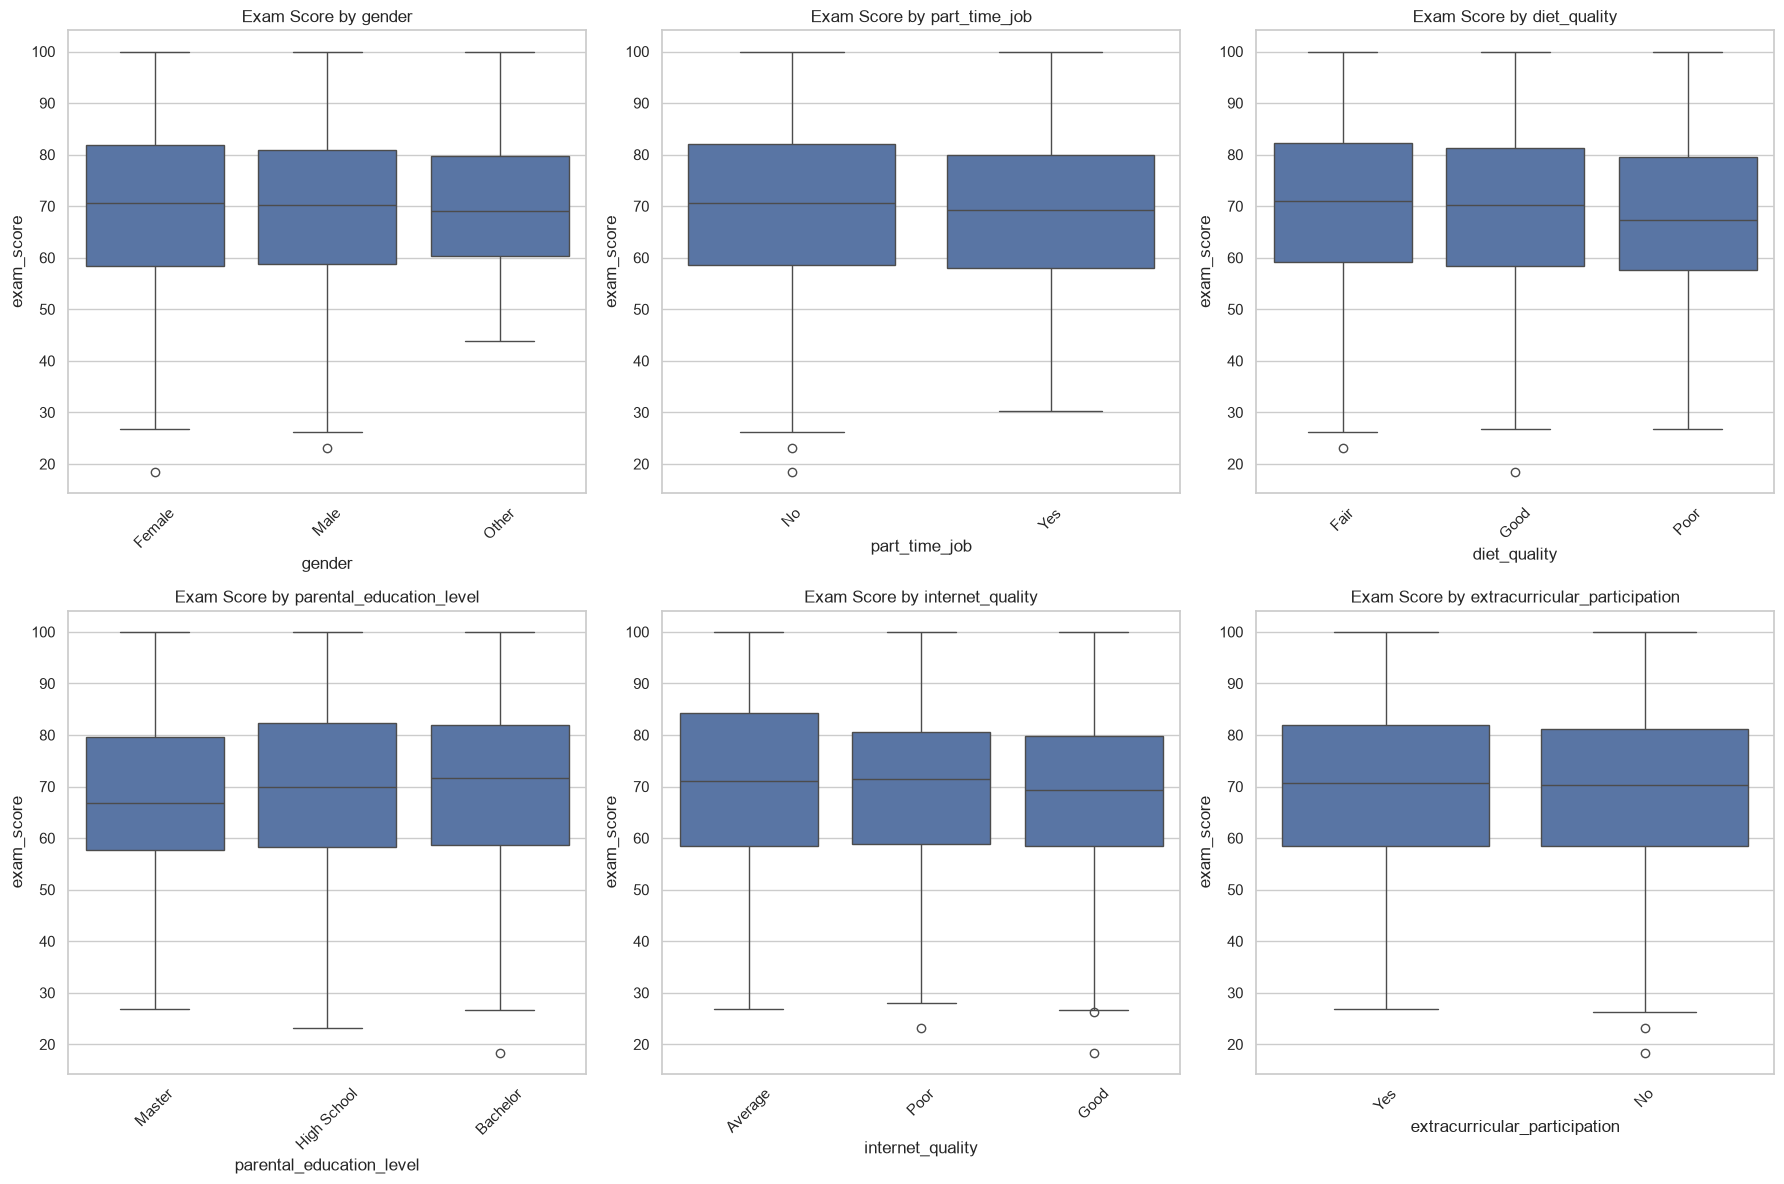

In [13]:
# Box plots: categorical features vs exam score
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.boxplot(data=df, x=col, y="exam_score", ax=axes[i])
    axes[i].set_title(f"Exam Score by {col}")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 🤖 Latest Model Results

Produced by `python train.py`. Re-run the script, then this cell, to refresh.

In [14]:
with open(ROOT / "models" / "model_meta.json", encoding="utf-8") as f:
    meta = json.load(f)

print(f"Selected model: {meta['model']} (tuned: {meta['tuned']}, engineered features: {meta['engineered_features']})")
print(f"CV RMSE: {meta['cv']['rmse']:.3f} +/- {meta['cv']['rmse_std']:.3f}   CV R2: {meta['cv']['r2']:.3f}")
print(f"Test RMSE: {meta['test_metrics']['rmse']:.3f}   Test R2: {meta['test_metrics']['r2']:.3f}")
print(f"{meta['interval']['level']:.0%} interval: +/- {meta['interval']['half_width']:.2f} "
      f"(test coverage {meta['test_metrics']['interval_coverage']:.1%})")

pd.DataFrame(meta["cv_leaderboard"])


Selected model: ridge (tuned: True, engineered features: False)
CV RMSE: 5.508 +/- 0.487   CV R2: 0.895
Test RMSE: 5.143   Test R2: 0.897
90% interval: +/- 8.60 (test coverage 91.5%)


,model,engineered,cv_rmse,cv_r2,tuned
0,ridge,False,5.508105,0.894748,True
1,ridge,False,5.518064,0.894358,False
2,linear_regression,False,5.520019,0.894283,False
3,gradient_boosting,True,5.665035,0.888982,True
4,gradient_boosting,True,5.982220,0.876165,False
5,xgboost,False,6.117657,0.870248,False
6,lightgbm,True,6.166026,0.868373,False
7,random_forest,True,6.491313,0.854104,False
